<a href="https://colab.research.google.com/github/mrayhanz/244107020027-Machine-Learning/blob/main/Minggu%2011/MRayhanZamzami_JS11_T1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IDENTITAS DIRI

Nama : Muhammad Rayhan Zamzami

NIM : 244107020027

Kelas : TI-3G

Absen : 19

# TUGAS PRAKTIKUM

Bagian 1: Komparasi Split dan Kernel pada voice.csv. Bagian 2: SVM RBF Fitur Histogram pada Citra Siang/Malam.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

df_voice = pd.read_csv('dataset/voice.csv')
X_voice = df_voice.iloc[:, :-1].values
y_voice = df_voice.iloc[:, -1].map({'male': 1, 'female': 0}).values
print('Ukuran voice dataset:', df_voice.shape)

Ukuran voice dataset: (3168, 21)


In [2]:
splits = {
    '70:30': 0.30,
    '80:20': 0.20
}

kernels = ['linear', 'poly', 'rbf']
results = []

for split_name, test_size in splits.items():
    X_train, X_test, y_train, y_test = train_test_split(
        X_voice, y_voice, test_size=test_size, random_state=42, stratify=y_voice
    )

    # Standardisasi fitur
    scaler = StandardScaler()
    X_train_sc = scaler.fit_transform(X_train)
    X_test_sc = scaler.transform(X_test)

    for k in kernels:
        model = SVC(kernel=k, random_state=42)
        model.fit(X_train_sc, y_train)

        acc_train = accuracy_score(y_train, model.predict(X_train_sc))
        acc_test = accuracy_score(y_test, model.predict(X_test_sc))

        results.append({
            'Rasio Split': split_name,
            'Kernel': k.upper(),
            'Akurasi Data Latih': f'{acc_train * 100:.2f}%',
            'Akurasi Data Uji': f'{acc_test * 100:.2f}%',
            'Score Numerik Latih': acc_train,
            'Score Numerik Uji': acc_test
        })

df_results = pd.DataFrame(results)
display(df_results[['Rasio Split', 'Kernel', 'Akurasi Data Latih', 'Akurasi Data Uji']])

,Rasio Split,Kernel,Akurasi Data Latih,Akurasi Data Uji
0,70:30,LINEAR,97.20%,97.90%
1,70:30,POLY,96.66%,96.00%
2,70:30,RBF,98.38%,98.32%
3,80:20,LINEAR,97.67%,97.48%
4,80:20,POLY,96.80%,95.58%
5,80:20,RBF,98.38%,98.26%


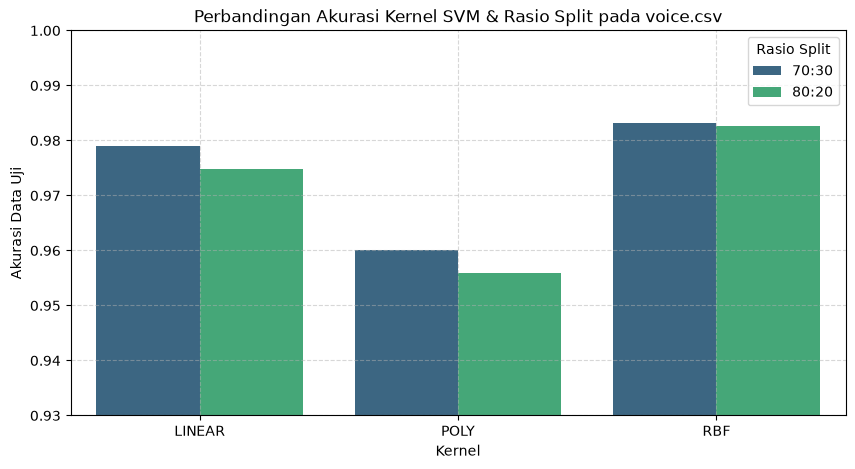

In [3]:
# Visualisasi perbandingan akurasi kernel dan split
plt.figure(figsize=(10, 5))
sns.barplot(data=df_results, x='Kernel', y='Score Numerik Uji', hue='Rasio Split', palette='viridis')
plt.ylim(0.93, 1.0)
plt.ylabel('Akurasi Data Uji')
plt.title('Perbandingan Akurasi Kernel SVM & Rasio Split pada voice.csv')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## SOAL 2: 

In [4]:
from pathlib import Path
import cv2
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline

# Fungsi ekstraksi fitur histogram multi-kanal HSV
def extract_hsv_histogram(img, bins_per_channel=32):
    img_res = cv2.resize(img, (256, 256))
    hsv = cv2.cvtColor(img_res, cv2.COLOR_BGR2HSV)
    hist_feats = []
    for c in range(3):
        hist = cv2.calcHist([hsv], [c], None, [bins_per_channel], [0, 256]).flatten()
        # Normalisasi L1
        hist = hist / (hist.sum() + 1e-7)
        hist_feats.extend(hist)
    return hist_feats

# Load citra training dan testing
train_p = Path('dataset/images/training') if Path('dataset/images/training').exists() else Path('images/training')
test_p = Path('dataset/images/test') if Path('dataset/images/test').exists() else Path('images/test')

def load_images_and_labels(folder):
    imgs, lbls = [], []
    for d in folder.glob('*'):
        if d.is_dir():
            for f in d.glob('*.jpg'):
                im = cv2.imread(str(f))
                if im is not None:
                    imgs.append(im)
                    lbls.append(1 if d.name == 'day' else 0)
    return imgs, lbls

train_imgs, train_lbls = load_images_and_labels(train_p)
test_imgs, test_lbls = load_images_and_labels(test_p)

# Gabung dan split rasio 80:20 sesuai instruksi
all_imgs = train_imgs + test_imgs
all_lbls = train_lbls + test_lbls

print(f'Total seluruh citra: {len(all_imgs)}')
X_hist = np.array([extract_hsv_histogram(im) for im in all_imgs])
y_hist = np.array(all_lbls)

X_train_img, X_test_img, y_train_img, y_test_img = train_test_split(
    X_hist, y_hist, test_size=0.20, random_state=42, stratify=y_hist
)
print('Dimensi data latih citra:', X_train_img.shape)
print('Dimensi data uji citra  :', X_test_img.shape)

Total seluruh citra: 400


Dimensi data latih citra: (320, 96)
Dimensi data uji citra  : (80, 96)


In [5]:
# Tuning hyperparameter C dan gamma pada SVM Kernel RBF
pipeline = make_pipeline(StandardScaler(), SVC(kernel='rbf'))

param_grid = {
    'svc__C': [0.1, 1, 10, 100],
    'svc__gamma': ['scale', 'auto', 0.01, 0.1, 1]
}

grid_cv = GridSearchCV(pipeline, param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_cv.fit(X_train_img, y_train_img)

print('Hyperparameter RBF Terbaik:', grid_cv.best_params_)
print(f'Akurasi 5-Fold Cross Validation: {grid_cv.best_score_ * 100:.2f}%')

best_img_model = grid_cv.best_estimator_
y_pred_img = best_img_model.predict(X_test_img)
test_acc_img = accuracy_score(y_test_img, y_pred_img)

print(f'Akurasi Data Uji (Rasio 80:20): {test_acc_img * 100:.2f}%')
print('\nLaporan Klasifikasi Citra Siang/Malam:')
print(classification_report(y_test_img, y_pred_img, target_names=['Malam', 'Siang']))

Hyperparameter RBF Terbaik: {'svc__C': 1, 'svc__gamma': 'scale'}
Akurasi 5-Fold Cross Validation: 99.38%
Akurasi Data Uji (Rasio 80:20): 98.75%

Laporan Klasifikasi Citra Siang/Malam:
              precision    recall  f1-score   support

       Malam       0.98      1.00      0.99        40
       Siang       1.00      0.97      0.99        40

    accuracy                           0.99        80
   macro avg       0.99      0.99      0.99        80
weighted avg       0.99      0.99      0.99        80

